In [19]:
# Step 0: Setting up the environment
# Loading required libraries

import random
import pandas as pd
import re
from pathlib import Path

import unicodedata
import numpy as np

import math
from collections import Counter, defaultdict
from itertools import islice

import matplotlib.pyplot as plt
import seaborn as sns

from nltk.tag.hmm import HiddenMarkovModelTrainer
from nltk.probability import LidstoneProbDist

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Setting seed for reproducibility

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Configuring paths to files

ENG_TRAIN_DIR = Path("./en_ewt-ud-train.conllu")
ENG_DEV_DIR = Path("./en_ewt-ud-dev.conllu")
ENG_TEST_DIR = Path("./en_ewt-ud-test.conllu")

IND_TRAIN_DIR = Path("./id_gsd-ud-train.conllu")
IND_DEV_DIR = Path("./id_gsd-ud-dev.conllu")
IND_TEST_DIR = Path("./id_gsd-ud-test.conllu")

print("Libraries and paths initialised.")

Libraries and paths initialised.


In [20]:
# Step 1: Loading the datasets

def load_conllu(file_path):
    """
    LoadS CoNLL-U file and extracts sentences, tokens and POS tags.
    Excludes multiword-token and empty-node entries.
    """

    sentences = []

    current_tokens = []
    current_pos = []

    with open(file_path, "r", encoding="utf-8") as file:

        for line in file:

            line = line.strip()

            # Blank line indicates sentence boundary
            if not line:
                if current_tokens:
                    sentence = " ".join(current_tokens)

                    sentences.append({
                        "text": sentence,
                        "tokens": current_tokens.copy(),
                        "pos_tags": current_pos.copy()
                    })

                    current_tokens.clear()
                    current_pos.clear()

                continue

            # Skip comments
            if line.startswith("#"):
                continue

            columns = line.split("\t")

            # CoNLL-U must contain 10 columns
            if len(columns) != 10:
                continue

            token_id = columns[0]
            word = columns[1]
            pos = columns[3]

            # Exclude multiword tokens (e.g. 1-2) and empty nodes (e.g. 1.1)
            if "-" in token_id or "." in token_id:
                continue

            if word == "_" or pos == "_":
                continue

            current_tokens.append(word)
            current_pos.append(pos)

        # Process final sentence if file lacks trailing blank line
        if current_tokens:
            sentences.append({
                "text": " ".join(current_tokens),
                "tokens": current_tokens.copy(),
                "pos_tags": current_pos.copy()
            })

    return pd.DataFrame(sentences)

eng_train_df = load_conllu(ENG_TRAIN_DIR)
eng_dev_df = load_conllu(ENG_DEV_DIR)
eng_test_df = load_conllu(ENG_TEST_DIR)

print("English datasets loaded.\n")

print("Total training set sentences:", len(eng_train_df))
print("Training set shape:", eng_train_df.shape)
print("Preview of training set:")
display(eng_train_df.head())


print("Total dev set sentences:", len(eng_dev_df))
print("Dev set shape:", eng_dev_df.shape)
print("Preview of dev set:")
display(eng_dev_df.head())


print("Total test set sentences:", len(eng_test_df))
print("Test set shape:", eng_test_df.shape)
print("Preview of test set:")
display(eng_test_df.head())



ind_train_df = load_conllu(IND_TRAIN_DIR)
ind_dev_df = load_conllu(IND_DEV_DIR)
ind_test_df = load_conllu(IND_TEST_DIR)

print("Indonesian datasets loaded.\n")
print("Total training set sentences:", len(ind_train_df))
print("Training set shape:", ind_train_df.shape)
print("Preview of training set:")
display(ind_train_df.head())

print("Total dev set sentences:", len(ind_dev_df))
print("Dev set shape:", ind_dev_df.shape)
print("Preview of dev set:")
display(ind_dev_df.head())

print("Total test set sentences:", len(ind_test_df))
print("Test set shape:", ind_test_df.shape)
print("Preview of test set:")
display(ind_test_df.head())

English datasets loaded.

Total training set sentences: 12544
Training set shape: (12544, 3)
Preview of training set:


,text,tokens,pos_tags
0,Al - Zaman : American forces killed Shaikh Abd...,"[Al, -, Zaman, :, American, forces, killed, Sh...","[PROPN, PUNCT, PROPN, PUNCT, ADJ, NOUN, VERB, ..."
1,[ This killing of a respected cleric will be c...,"[[, This, killing, of, a, respected, cleric, w...","[PUNCT, DET, NOUN, ADP, DET, ADJ, NOUN, AUX, A..."
2,DPA : Iraqi authorities announced that they ha...,"[DPA, :, Iraqi, authorities, announced, that, ...","[PROPN, PUNCT, ADJ, NOUN, VERB, SCONJ, PRON, A..."
3,Two of them were being run by 2 officials of t...,"[Two, of, them, were, being, run, by, 2, offic...","[NUM, ADP, PRON, AUX, AUX, VERB, ADP, NUM, NOU..."
4,"The MoI in Iraq is equivalent to the US FBI , ...","[The, MoI, in, Iraq, is, equivalent, to, the, ...","[DET, PROPN, ADP, PROPN, AUX, ADJ, ADP, DET, P..."


Total dev set sentences: 2001
Dev set shape: (2001, 3)
Preview of dev set:


,text,tokens,pos_tags
0,From the AP comes this story :,"[From, the, AP, comes, this, story, :]","[ADP, DET, PROPN, VERB, DET, NOUN, PUNCT]"
1,President Bush on Tuesday nominated two indivi...,"[President, Bush, on, Tuesday, nominated, two,...","[PROPN, PROPN, ADP, PROPN, VERB, NUM, NOUN, PA..."
2,Bush nominated Jennifer M. Anderson for a 15 -...,"[Bush, nominated, Jennifer, M., Anderson, for,...","[PROPN, VERB, PROPN, PROPN, PROPN, ADP, DET, N..."
3,***,[***],[PUNCT]
4,Bush also nominated A. Noel Anketell Kramer fo...,"[Bush, also, nominated, A., Noel, Anketell, Kr...","[PROPN, ADV, VERB, PROPN, PROPN, PROPN, PROPN,..."


Total test set sentences: 2077
Test set shape: (2077, 3)
Preview of test set:


,text,tokens,pos_tags
0,What if Google Morphed Into GoogleOS ?,"[What, if, Google, Morphed, Into, GoogleOS, ?]","[PRON, SCONJ, PROPN, VERB, ADP, PROPN, PUNCT]"
1,What if Google expanded on its search - engine...,"[What, if, Google, expanded, on, its, search, ...","[PRON, SCONJ, PROPN, VERB, ADP, PRON, NOUN, PU..."
2,[ via Microsoft Watch from Mary Jo Foley ],"[[, via, Microsoft, Watch, from, Mary, Jo, Fol...","[PUNCT, ADP, PROPN, PROPN, ADP, PROPN, PROPN, ..."
3,"( And , by the way , is anybody else just a li...","[(, And, ,, by, the, way, ,, is, anybody, else...","[PUNCT, CCONJ, PUNCT, ADP, DET, NOUN, PUNCT, A..."
4,This BuzzMachine post argues that Google 's ru...,"[This, BuzzMachine, post, argues, that, Google...","[DET, PROPN, NOUN, VERB, SCONJ, PROPN, PART, N..."


... (2 outputs left out)

Total dev set sentences: 559
Dev set shape: (559, 3)
Preview of dev set:


,text,tokens,pos_tags
0,Ahli rekayasa optik mendesain komponen dari in...,"[Ahli, rekayasa, optik, mendesain, komponen, d...","[PROPN, NOUN, NOUN, VERB, NOUN, ADP, NOUN, ADJ..."
1,"Wisma Kalla terletak di kota makassar , tak ja...","[Wisma, Kalla, terletak, di, kota, makassar, ,...","[PROPN, PROPN, VERB, ADP, NOUN, ADJ, PUNCT, PA..."
2,Hal tersebut dapat dilihat dalam beberapa cont...,"[Hal, tersebut, dapat, dilihat, dalam, beberap...","[NOUN, DET, AUX, VERB, ADP, DET, NOUN, NOUN, P..."
3,Sedangkan Permintaan adalah keinginan akan ses...,"[Sedangkan, Permintaan, adalah, keinginan, aka...","[SCONJ, PROPN, AUX, NOUN, ADP, PRON, PRON, VER..."
4,Let It Shine adalah film televisi 2012 .,"[Let, It, Shine, adalah, film, televisi, 2012, .]","[PROPN, PROPN, PROPN, AUX, NOUN, NOUN, NUM, PU..."


Total test set sentences: 557
Test set shape: (557, 3)
Preview of test set:


,text,tokens,pos_tags
0,Sampul dari dua singel pertama difoto oleh Emm...,"[Sampul, dari, dua, singel, pertama, difoto, o...","[NOUN, ADP, NUM, NOUN, ADJ, VERB, ADP, PROPN, ..."
1,Baler adalah munisipalitas yang terletak di pr...,"[Baler, adalah, munisipalitas, yang, terletak,...","[PROPN, AUX, NOUN, PRON, VERB, ADP, PROPN, PRO..."
2,Bagaimana sejarah berdiri nya SMAN 1 Pekanbaru...,"[Bagaimana, sejarah, berdiri, nya, SMAN, 1, Pe...","[ADV, NOUN, NOUN, PRON, PROPN, NUM, PROPN, PRO..."
3,Pencurian dan perampokan juga sangat jarang te...,"[Pencurian, dan, perampokan, juga, sangat, jar...","[NOUN, CCONJ, NOUN, ADV, ADV, ADV, VERB, ADP, ..."
4,Dalam lima tahun sejak panggilan of Duty 4 ber...,"[Dalam, lima, tahun, sejak, panggilan, of, Dut...","[ADP, NUM, NOUN, ADP, NOUN, PROPN, PROPN, NUM,..."


In [21]:
# Step 2: Data Cleaning and Preprocessing

def clean_conllu_dataframe(df, min_textual_tokens=3):

    cleaned_records = []

    for _, row in df.iterrows():

        cleaned_tokens = []
        cleaned_pos = []

        for token, pos in zip(row["tokens"], row["pos_tags"]):

            token = unicodedata.normalize("NFC", token).strip()

            if not token:
                continue

            cleaned_tokens.append(token)
            cleaned_pos.append(pos)

        # Count tokens containing alphabetic characters
        textual_count = sum(
            1 for token in cleaned_tokens
            if re.search(r"[^\W\d_]", token, flags=re.UNICODE)
        )

        if textual_count < min_textual_tokens:
            continue

        cleaned_records.append({
            "text": " ".join(cleaned_tokens),
            "tokens": cleaned_tokens,
            "pos_tags": cleaned_pos
        })

    result = pd.DataFrame(
        cleaned_records,
        columns=["text", "tokens", "pos_tags"]
    )

    # Remove duplicate sentences while retaining aligned annotations
    result = result.drop_duplicates(
        subset=["text"]
    ).reset_index(drop=True)

    return result


# English cleaned splits
eng_train = clean_conllu_dataframe(eng_train_df)
eng_dev = clean_conllu_dataframe(eng_dev_df)
eng_test = clean_conllu_dataframe(eng_test_df)

print("English datasets cleaned.\n")
print("Cleaned training set sentences:", len(eng_train))
print("Cleaned training set shape:", eng_train.shape)
print("Cleaned training set preview:")
display(eng_train.head())


print("Cleaned dev set sentences:", len(eng_dev))
print("Cleaned dev set shape:", eng_dev.shape)
print("Cleaned dev set preview:")
display(eng_dev.head())


print("Cleaned test set sentences:", len(eng_test))
print("Cleaned test set shape:", eng_test.shape)
print("Cleaned test set preview:")
display(eng_test.head())


# Indonesian cleaned splits
ind_train = clean_conllu_dataframe(ind_train_df)
ind_dev = clean_conllu_dataframe(ind_dev_df)
ind_test = clean_conllu_dataframe(ind_test_df)

print("Indonesian datasets cleaned.\n")
print("Cleaned training set sentences:", len(ind_train))
print("Cleaned training set shape:", ind_train.shape)
print("Cleaned training set preview:")
display(ind_train.head())


print("Cleaned dev set sentences:", len(ind_dev))
print("Cleaned dev set shape:", ind_dev.shape)
print("Cleaned dev set preview:")
display(ind_dev.head())


print("Cleaned test set sentences:", len(ind_test))
print("Cleaned test set shape:", ind_test.shape)
print("Cleaned test set preview:")
display(ind_test.head())

English datasets cleaned.

Cleaned training set sentences: 10596
Cleaned training set shape: (10596, 3)
Cleaned training set preview:


,text,tokens,pos_tags
0,Al - Zaman : American forces killed Shaikh Abd...,"[Al, -, Zaman, :, American, forces, killed, Sh...","[PROPN, PUNCT, PROPN, PUNCT, ADJ, NOUN, VERB, ..."
1,[ This killing of a respected cleric will be c...,"[[, This, killing, of, a, respected, cleric, w...","[PUNCT, DET, NOUN, ADP, DET, ADJ, NOUN, AUX, A..."
2,DPA : Iraqi authorities announced that they ha...,"[DPA, :, Iraqi, authorities, announced, that, ...","[PROPN, PUNCT, ADJ, NOUN, VERB, SCONJ, PRON, A..."
3,Two of them were being run by 2 officials of t...,"[Two, of, them, were, being, run, by, 2, offic...","[NUM, ADP, PRON, AUX, AUX, VERB, ADP, NUM, NOU..."
4,"The MoI in Iraq is equivalent to the US FBI , ...","[The, MoI, in, Iraq, is, equivalent, to, the, ...","[DET, PROPN, ADP, PROPN, AUX, ADJ, ADP, DET, P..."


Cleaned dev set sentences: 1628
Cleaned dev set shape: (1628, 3)
Cleaned dev set preview:


,text,tokens,pos_tags
0,From the AP comes this story :,"[From, the, AP, comes, this, story, :]","[ADP, DET, PROPN, VERB, DET, NOUN, PUNCT]"
1,President Bush on Tuesday nominated two indivi...,"[President, Bush, on, Tuesday, nominated, two,...","[PROPN, PROPN, ADP, PROPN, VERB, NUM, NOUN, PA..."
2,Bush nominated Jennifer M. Anderson for a 15 -...,"[Bush, nominated, Jennifer, M., Anderson, for,...","[PROPN, VERB, PROPN, PROPN, PROPN, ADP, DET, N..."
3,Bush also nominated A. Noel Anketell Kramer fo...,"[Bush, also, nominated, A., Noel, Anketell, Kr...","[PROPN, ADV, VERB, PROPN, PROPN, PROPN, PROPN,..."
4,The sheikh in wheel - chair has been attacked ...,"[The, sheikh, in, wheel, -, chair, has, been, ...","[DET, NOUN, ADP, NOUN, PUNCT, NOUN, AUX, AUX, ..."


Cleaned test set sentences: 1630
Cleaned test set shape: (1630, 3)
Cleaned test set preview:


,text,tokens,pos_tags
0,What if Google Morphed Into GoogleOS ?,"[What, if, Google, Morphed, Into, GoogleOS, ?]","[PRON, SCONJ, PROPN, VERB, ADP, PROPN, PUNCT]"
1,What if Google expanded on its search - engine...,"[What, if, Google, expanded, on, its, search, ...","[PRON, SCONJ, PROPN, VERB, ADP, PRON, NOUN, PU..."
2,[ via Microsoft Watch from Mary Jo Foley ],"[[, via, Microsoft, Watch, from, Mary, Jo, Fol...","[PUNCT, ADP, PROPN, PROPN, ADP, PROPN, PROPN, ..."
3,"( And , by the way , is anybody else just a li...","[(, And, ,, by, the, way, ,, is, anybody, else...","[PUNCT, CCONJ, PUNCT, ADP, DET, NOUN, PUNCT, A..."
4,This BuzzMachine post argues that Google 's ru...,"[This, BuzzMachine, post, argues, that, Google...","[DET, PROPN, NOUN, VERB, SCONJ, PROPN, PART, N..."


... (2 outputs left out)

Cleaned dev set sentences: 555
Cleaned dev set shape: (555, 3)
Cleaned dev set preview:


,text,tokens,pos_tags
0,Ahli rekayasa optik mendesain komponen dari in...,"[Ahli, rekayasa, optik, mendesain, komponen, d...","[PROPN, NOUN, NOUN, VERB, NOUN, ADP, NOUN, ADJ..."
1,"Wisma Kalla terletak di kota makassar , tak ja...","[Wisma, Kalla, terletak, di, kota, makassar, ,...","[PROPN, PROPN, VERB, ADP, NOUN, ADJ, PUNCT, PA..."
2,Hal tersebut dapat dilihat dalam beberapa cont...,"[Hal, tersebut, dapat, dilihat, dalam, beberap...","[NOUN, DET, AUX, VERB, ADP, DET, NOUN, NOUN, P..."
3,Sedangkan Permintaan adalah keinginan akan ses...,"[Sedangkan, Permintaan, adalah, keinginan, aka...","[SCONJ, PROPN, AUX, NOUN, ADP, PRON, PRON, VER..."
4,Let It Shine adalah film televisi 2012 .,"[Let, It, Shine, adalah, film, televisi, 2012, .]","[PROPN, PROPN, PROPN, AUX, NOUN, NOUN, NUM, PU..."


Cleaned test set sentences: 554
Cleaned test set shape: (554, 3)
Cleaned test set preview:


,text,tokens,pos_tags
0,Sampul dari dua singel pertama difoto oleh Emm...,"[Sampul, dari, dua, singel, pertama, difoto, o...","[NOUN, ADP, NUM, NOUN, ADJ, VERB, ADP, PROPN, ..."
1,Baler adalah munisipalitas yang terletak di pr...,"[Baler, adalah, munisipalitas, yang, terletak,...","[PROPN, AUX, NOUN, PRON, VERB, ADP, PROPN, PRO..."
2,Bagaimana sejarah berdiri nya SMAN 1 Pekanbaru...,"[Bagaimana, sejarah, berdiri, nya, SMAN, 1, Pe...","[ADV, NOUN, NOUN, PRON, PROPN, NUM, PROPN, PRO..."
3,Pencurian dan perampokan juga sangat jarang te...,"[Pencurian, dan, perampokan, juga, sangat, jar...","[NOUN, CCONJ, NOUN, ADV, ADV, ADV, VERB, ADP, ..."
4,Dalam lima tahun sejak panggilan of Duty 4 ber...,"[Dalam, lima, tahun, sejak, panggilan, of, Dut...","[ADP, NUM, NOUN, ADP, NOUN, PROPN, PROPN, NUM,..."


In [22]:
# Step 3: Text Preprocessing for N-gram modelling

def build_vocabulary(df):
    """
    Build vocabulary using training sentences only.
    """
    vocab = set()

    for tokens in df["tokens"]:
        vocab.update(tokens)

    # Reserve unknown and sentence boundary tokens
    vocab.add("<UNK>")
    vocab.add("<s>")
    vocab.add("</s>")

    return vocab


def prepare_sentences(df, vocab):
    """
    Convert sentences into padded token sequences.
    Unknown words are replaced with <UNK>.
    """

    sentences = []

    for tokens in df["tokens"]:

        processed_tokens = [
            token if token in vocab else "<UNK>"
            for token in tokens
        ]

        sentence = (
            ["<s>", "<s>"]
            + processed_tokens
            + ["</s>"]
        )

        sentences.append(sentence)

    return sentences


# English vocabulary and splits
eng_vocab = build_vocabulary(eng_train)
eng_prediction_vocab = eng_vocab - {"<s>"}

eng_train_sentences = prepare_sentences(eng_train, eng_vocab)
eng_dev_sentences = prepare_sentences(eng_dev, eng_vocab)
eng_test_sentences = prepare_sentences(eng_test, eng_vocab)

eng_vocab_size = len(eng_vocab)


# Indonesian vocabulary and splits
ind_vocab = build_vocabulary(ind_train)
ind_prediction_vocab = ind_vocab - {"<s>"}

ind_train_sentences = prepare_sentences(ind_train, ind_vocab)
ind_dev_sentences = prepare_sentences(ind_dev, ind_vocab)
ind_test_sentences = prepare_sentences(ind_test, ind_vocab)

ind_vocab_size = len(ind_vocab)


# Display dataset statistics
print("English vocabulary:", eng_vocab_size)
print("Indonesian vocabulary:", ind_vocab_size)

print("\nEnglish training sentences:", len(eng_train_sentences))
print("English development sentences:", len(eng_dev_sentences))
print("English test sentences:", len(eng_test_sentences))

print("\nIndonesian training sentences:", len(ind_train_sentences))
print("Indonesian development sentences:", len(ind_dev_sentences))
print("Indonesian test sentences:", len(ind_test_sentences))


# Preview processed sentences
def preview_sentences(sentences, language, num_samples=5):
    """
    Display a preview of processed sentences.
    """
    print(f"\n{'=' * 70}")
    print(f"{language} - Processed Sentence Preview")
    print(f"{'=' * 70}")

    for i, sentence in enumerate(sentences[:num_samples], start=1):
        print(f"\nSentence {i}:")
        print(" ".join(sentence))


# Preview the training sentences
preview_sentences(eng_train_sentences, "English")
preview_sentences(ind_train_sentences, "Indonesian")

English vocabulary: 18967
Indonesian vocabulary: 18768

English training sentences: 10596
English development sentences: 1628
English test sentences: 1630

Indonesian training sentences: 4451
Indonesian development sentences: 555
Indonesian test sentences: 554

English - Processed Sentence Preview

Sentence 1:
<s> <s> Al - Zaman : American forces killed Shaikh Abdullah al - Ani , the preacher at the mosque in the town of Qaim , near the Syrian border . </s>

Sentence 2:
<s> <s> [ This killing of a respected cleric will be causing us trouble for years to come . ] </s>

Sentence 3:
<s> <s> DPA : Iraqi authorities announced that they had busted up 3 terrorist cells operating in Baghdad . </s>

Sentence 4:
<s> <s> Two of them were being run by 2 officials of the Ministry of the Interior ! </s>

Sentence 5:
<s> <s> The MoI in Iraq is equivalent to the US FBI , so this would be like having J. Edgar Hoover unwittingly employ at a high level members of the Weathermen bombers back in the 1960s 

In [23]:
# Step 4: Generate N-gram frequencies

def build_ngram(sentences):

    ngram_counts = {
        1: Counter(),
        2: Counter(),
        3: Counter()
    }

    context_counts = {
        1: Counter(),
        2: Counter(),
        3: Counter()
    }

    for sentence in sentences:

        for n in range(1, 4):

            for i in range(len(sentence) - n + 1):

                ngram = tuple(sentence[i:i+n])

                ngram_counts[n][ngram] += 1

                if n > 1:
                    context = tuple(sentence[i:i+n-1])
                    context_counts[n][context] += 1

    return ngram_counts, context_counts


# English training counts
eng_ngram_counts, eng_context_counts = build_ngram(
    eng_train_sentences
)

# Indonesian training counts
ind_ngram_counts, ind_context_counts = build_ngram(
    ind_train_sentences
)

# Function to display top n-grams for each language
def display_top_ngrams(ngram_counts, language):

    print(f"\n{language} N-gram Frequencies")

    for n in range(1, 4):

        print(f"\nTop {n}-gram sequences:")

        for ngram, count in ngram_counts[n].most_common(10):
            print(f"{ngram}: {count}")

# Display top n-grams
display_top_ngrams(eng_ngram_counts, "English-EWT")
display_top_ngrams(ind_ngram_counts, "Indonesian-GSD")


English-EWT N-gram Frequencies

Top 1-gram sequences:
('<s>',): 21192
('</s>',): 10596
('.',): 8237
('the',): 7989
(',',): 6709
('to',): 4972
('and',): 4775
('a',): 3542
('of',): 3535
('I',): 3044

Top 2-gram sequences:
('<s>', '<s>'): 10596
('.', '</s>'): 7937
('<s>', 'I'): 1346
('of', 'the'): 857
('<s>', 'The'): 747
('in', 'the'): 689
(',', 'and'): 668
('?', '</s>'): 660
('to', 'the'): 436
('!', '</s>'): 422

Top 3-gram sequences:
('<s>', '<s>', 'I'): 1346
('<s>', '<s>', 'The'): 747
('<s>', '<s>', 'It'): 320
('<s>', '<s>', 'We'): 277
('<s>', '<s>', 'They'): 237
('<s>', '<s>', 'If'): 227
('<s>', '<s>', 'This'): 196
(')', '.', '</s>'): 187
('<s>', '<s>', 'He'): 179
('<s>', '<s>', 'You'): 178

Indonesian-GSD N-gram Frequencies

Top 1-gram sequences:
('<s>',): 8902
(',',): 5164
('.',): 4472
('</s>',): 4451
('yang',): 2428
('dan',): 2210
('di',): 1804
('nya',): 1356
('ini',): 922
('dengan',): 901

Top 2-gram sequences:
('<s>', '<s>'): 4451
('.', '</s>'): 3936
('?', '</s>'): 459
(',', 'da

In [24]:
# Step 5: N-gram Probability Estimation

# Step 5A: Maximum Likelihood Estimation (MLE)
def mle_prob(ngram, ngram_counts, context_counts):

    n = len(ngram)
    count = ngram_counts[n].get(ngram, 0)

    if n == 1:
        total = sum(ngram_counts[1].values())
        return count / total if total > 0 else 0

    context = ngram[:-1]
    context_count = context_counts[n].get(context, 0)

    return count / context_count if context_count > 0 else 0


# Step 5B: Laplace Smoothing
def laplace_prob(
    ngram,
    ngram_counts,
    context_counts,
    vocab_size
):

    n = len(ngram)
    count = ngram_counts[n].get(ngram, 0)

    if n == 1:
        total = sum(ngram_counts[1].values())
        return (count + 1) / (total + vocab_size)

    context = ngram[:-1]
    context_count = context_counts[n].get(context, 0)

    return (count + 1) / (context_count + vocab_size)

# Step 5C: Linear Interpolation Smoothing
def interpolation_probability(
    ngram,
    ngram_counts,
    context_counts,
    lambdas=(0.5, 0.3, 0.2)
):

    n = len(ngram)

    if n == 1:
        return mle_prob(
            ngram, ngram_counts, context_counts
        )

    probability = 0

    # Calculate probabilities from lower to higher orders
    for order in range(1, n + 1):

        sub_ngram = ngram[-order:]

        p = mle_prob(
            sub_ngram,
            ngram_counts,
            context_counts
        )

        probability += lambdas[order - 1] * p

    return probability

# Step 5D: Generate Probability Comparison Table
def generate_comparison_table(
    ngram_counts,
    context_counts,
    vocab_size,
    language
):

    rows = []

    for n in range(1, 4):

        for ngram, count in ngram_counts[n].most_common(20):

            mle = mle_prob(
                ngram, ngram_counts, context_counts
            )

            laplace = laplace_prob(
                ngram,
                ngram_counts,
                context_counts,
                vocab_size
            )

            interpolation = interpolation_probability(
                ngram, ngram_counts, context_counts
            )

            rows.append({
                "Language": language,
                "N-gram Order": n,
                "N-gram": " ".join(ngram),
                "Frequency": count,
                "MLE": round(mle, 6),
                "Laplace": round(laplace, 6),
                "Interpolation": round(interpolation, 6),
            })

    return pd.DataFrame(rows)


# English comparison
eng_compare = generate_comparison_table(
    eng_ngram_counts,
    eng_context_counts,
    eng_vocab_size - 1,
    "English"
)

# Indonesian comparison
ind_compare = generate_comparison_table(
    ind_ngram_counts,
    ind_context_counts,
    ind_vocab_size - 1,
    "Indonesian"
)


# Display results
print("English N-gram Probability Comparison")
display(eng_compare)

print("Indonesian N-gram Probability Comparison")
display(ind_compare)

English N-gram Probability Comparison


,Language,N-gram Order,N-gram,Frequency,MLE,Laplace,Interpolation
0,English,1,<s>,21192,0.092760,0.085654,0.092760
1,English,1,</s>,10596,0.046380,0.042829,0.046380
2,English,1,.,8237,0.036054,0.033295,0.036054
3,English,1,the,7989,0.034969,0.032292,0.034969
4,English,1,",",6709,0.029366,0.027119,0.029366
5,English,1,to,4972,0.021763,0.020099,0.021763
6,English,1,and,4775,0.020901,0.019303,0.020901
7,English,1,a,3542,0.015504,0.014319,0.015504
8,English,1,of,3535,0.015473,0.014291,0.015473
9,English,1,I,3044,0.013324,0.012307,0.013324


Indonesian N-gram Probability Comparison


,Language,N-gram Order,N-gram,Frequency,MLE,Laplace,Interpolation
0,Indonesian,1,<s>,8902,0.080353,0.068721,0.080353
1,Indonesian,1,",",5164,0.046612,0.039868,0.046612
2,Indonesian,1,.,4472,0.040366,0.034526,0.040366
3,Indonesian,1,</s>,4451,0.040177,0.034364,0.040177
4,Indonesian,1,yang,2428,0.021916,0.018749,0.021916
5,Indonesian,1,dan,2210,0.019948,0.017066,0.019948
6,Indonesian,1,di,1804,0.016284,0.013933,0.016284
7,Indonesian,1,nya,1356,0.012240,0.010474,0.012240
8,Indonesian,1,ini,922,0.008322,0.007124,0.008322
9,Indonesian,1,dengan,901,0.008133,0.006962,0.008133


In [25]:
# Step 6: Sentence Generation
def generate_sentence(
    ngram_counts,
    context_counts,
    vocab,
    max_words=20
):

    sentence = ["<s>", "<s>"]

    for _ in range(max_words):

        context = sentence[-2:]

        candidates = []
        probabilities = []

        for word in vocab:

            if word == "<s>":
                continue

            trigram = tuple(context + [word])

            p = interpolation_probability(
                trigram,
                ngram_counts,
                context_counts
            )

            if p > 0:
                candidates.append(word)
                probabilities.append(p)

        if not candidates:
            break

        # Select the next word based on its probability
        next_word = random.choices(
            candidates,
            weights=probabilities,
            k=1
        )[0]

        if next_word == "</s>":
            break

        sentence.append(next_word)

    # Remove sentence-start markers
    generated_tokens = [
        word for word in sentence
        if word != "<s>"
    ]

    return " ".join(generated_tokens)

# ==========================================================
# Generate Five Sentences for Each Dataset
# ==========================================================

print("=" * 60)
print("GENERATED ENGLISH SENTENCES")
print("=" * 60)

for i in range(5):

    generated = generate_sentence(
        eng_ngram_counts,
        eng_context_counts,
        eng_prediction_vocab,
        max_words=20
    )


    print(f"{i + 1}. {generated}")


print("\n" + "=" * 60)
print("GENERATED INDONESIAN SENTENCES")
print("=" * 60)

for i in range(5):

    generated = generate_sentence(
        ind_ngram_counts,
        ind_context_counts,
        ind_prediction_vocab,
        max_words=20
    )

    print(f"{i + 1}. {generated}")

GENERATED ENGLISH SENTENCES
1. 217 The never easy before . nothing were trying in
2. he says c'm you nerve would attack . same positions they a I found Bush referred cheaply as no .
3. If you Do n't stand be the crate , the situation sell liquor following quote first ... them and you
4. I was not the most peaceful ,
5. Nothing those the look days after Sat. risk in our

GENERATED INDONESIAN SENTENCES
1. termasuk menjual muda tahun , - Ahbar , seorang dilakukan , dan Goenoeng si harimau karena saat ia bagi rakyat
2. Di mie , aktor top SP2010 sampai SPM tidak memiliki angka 50.000 kopi 549 suara , melainkan James menyarankan buatan
3. muncul Thomas Ir Operasi Bagration .
4. militer dari dan Cina memanggil nya sering Tenggara desa Sidapurna atau lempah , Alkitab mingguan oleh Penelitian ilmiah sebagai Agustus
5. . , Letjen TNI Marciano Norman memiliki status ( Japah maka pohon Candi itu , kurangnya waktu bagi diterbitkan di


In [26]:
# Step 7: POS Tagging with HMM
def find_pos_column(df):

    possible_columns = [
        "upos",
        "pos",
        "pos_tags",
        "tags",
        "upos_tags"
    ]

    for column in possible_columns:
        if column in df.columns:
            return column

    raise ValueError(
        f"No POS column found. Available columns: {list(df.columns)}"
    )


# Convert DataFrame into tagged sentences
def extract_tagged_sentences(df):

    pos_column = find_pos_column(df)

    tagged_sentences = []

    for _, row in df.iterrows():

        tokens = row["tokens"]
        tags = row[pos_column]

        # Skip invalid or empty entries
        if not isinstance(tokens, (list, tuple)):
            continue

        if not isinstance(tags, (list, tuple)):
            continue

        # Ensure tokens and tags are aligned
        if len(tokens) != len(tags) or len(tokens) == 0:
            continue

        sentence = [
            (str(word), str(tag))
            for word, tag in zip(tokens, tags)
        ]

        tagged_sentences.append(sentence)

    return tagged_sentences


# Extract English and Indonesian sentences
eng_train_tagged = extract_tagged_sentences(eng_train)
eng_test_tagged = extract_tagged_sentences(eng_test)

ind_train_tagged = extract_tagged_sentences(ind_train)
ind_test_tagged = extract_tagged_sentences(ind_test)


# Display dataset information
print("English training sentences:", len(eng_train_tagged))
print("English test sentences:", len(eng_test_tagged))

print("Indonesian training sentences:", len(ind_train_tagged))
print("Indonesian test sentences:", len(ind_test_tagged))


# Preview sentence
print("\nEnglish example:")
print(eng_train_tagged[0])

print("\nIndonesian example:")
print(ind_train_tagged[0])

English training sentences: 10596
English test sentences: 1630
Indonesian training sentences: 4451
Indonesian test sentences: 554

English example:
[('Al', 'PROPN'), ('-', 'PUNCT'), ('Zaman', 'PROPN'), (':', 'PUNCT'), ('American', 'ADJ'), ('forces', 'NOUN'), ('killed', 'VERB'), ('Shaikh', 'PROPN'), ('Abdullah', 'PROPN'), ('al', 'PROPN'), ('-', 'PUNCT'), ('Ani', 'PROPN'), (',', 'PUNCT'), ('the', 'DET'), ('preacher', 'NOUN'), ('at', 'ADP'), ('the', 'DET'), ('mosque', 'NOUN'), ('in', 'ADP'), ('the', 'DET'), ('town', 'NOUN'), ('of', 'ADP'), ('Qaim', 'PROPN'), (',', 'PUNCT'), ('near', 'ADP'), ('the', 'DET'), ('Syrian', 'ADJ'), ('border', 'NOUN'), ('.', 'PUNCT')]

Indonesian example:
[('Sembungan', 'PROPN'), ('adalah', 'AUX'), ('sebuah', 'DET'), ('desa', 'NOUN'), ('yang', 'PRON'), ('terletak', 'VERB'), ('di', 'ADP'), ('kecamatan', 'NOUN'), ('Kejajar', 'PROPN'), (',', 'PUNCT'), ('kabupaten', 'NOUN'), ('Wonosobo', 'PROPN'), (',', 'PUNCT'), ('Jawa', 'PROPN'), ('Tengah', 'PROPN'), (',', 'PUNCT')

In [27]:
# Build vocabulary from training data
def build_word_vocabulary(tagged_sentences, min_freq=2):

    word_counts = Counter(
        word
        for sentence in tagged_sentences
        for word, tag in sentence
    )

    vocabulary = {
        word
        for word, count in word_counts.items()
        if count >= min_freq
    }

    return vocabulary

# Replace rare and unseen words
def replace_unknown_words(tagged_sentences, vocabulary):

    processed_sentences = []

    for sentence in tagged_sentences:

        processed_sentence = []

        for word, tag in sentence:

            if word not in vocabulary:
                word = "<UNK>"

            processed_sentence.append((word, tag))

        processed_sentences.append(processed_sentence)

    return processed_sentences

# Prepare English data
eng_vocab = build_word_vocabulary(eng_train_tagged)

eng_train_processed = replace_unknown_words(
    eng_train_tagged, eng_vocab
)

eng_test_processed = replace_unknown_words(
    eng_test_tagged, eng_vocab
)

# Prepare Indonesian data
ind_vocab = build_word_vocabulary(ind_train_tagged)

ind_train_processed = replace_unknown_words(
    ind_train_tagged, ind_vocab
)

ind_test_processed = replace_unknown_words(
    ind_test_tagged, ind_vocab
)


# Display vocabulary information
print("English vocabulary size:", len(eng_vocab))
print("Indonesian vocabulary size:", len(ind_vocab))

print(
    "English unknown training tokens:",
    sum(word == "<UNK>"
        for sentence in eng_train_processed
        for word, tag in sentence)
)

print(
    "Indonesian unknown training tokens:",
    sum(word == "<UNK>"
        for sentence in ind_train_processed
        for word, tag in sentence)
)

English vocabulary size: 9413
Indonesian vocabulary size: 7161
English unknown training tokens: 9551
Indonesian unknown training tokens: 11604


In [28]:
# HMM training function

def train_hmm(train_data, gamma=0.1):

    trainer = HiddenMarkovModelTrainer()

    model = trainer.train_supervised(
        train_data,
        estimator=lambda fd, bins: LidstoneProbDist(
            fd,
            gamma,
            bins
        )
    )

    return model

# Train English HMM
eng_hmm = train_hmm(eng_train_processed)

print("English HMM training completed.")


# Train Indonesian HMM
ind_hmm = train_hmm(ind_train_processed)

print("Indonesian HMM training completed.")

English HMM training completed.
Indonesian HMM training completed.


In [29]:
# HMM Prediction function
def predict_hmm(model, test_data):

    predictions = []

    for sentence in test_data:

        words = [word for word, tag in sentence]

        predicted_tags = model.tag(words)

        predictions.append(predicted_tags)

    return predictions

# English predictions
eng_predictions = predict_hmm(
    eng_hmm,
    eng_test_processed
)


# Indonesian predictions
ind_predictions = predict_hmm(
    ind_hmm,
    ind_test_processed
)


print("English POS prediction completed.")
print("Indonesian POS prediction completed.")


# Preview prediction
print("\nEnglish example:")
print("Actual:", eng_test_processed[0])
print("Predicted:", eng_predictions[0])

print("\nIndonesian example:")
print("Actual:", ind_test_processed[0])
print("Predicted:", ind_predictions[0])

English POS prediction completed.
Indonesian POS prediction completed.

English example:
Actual: [('What', 'PRON'), ('if', 'SCONJ'), ('Google', 'PROPN'), ('<UNK>', 'VERB'), ('<UNK>', 'ADP'), ('<UNK>', 'PROPN'), ('?', 'PUNCT')]
Predicted: [('What', 'PRON'), ('if', 'SCONJ'), ('Google', 'PROPN'), ('<UNK>', 'PROPN'), ('<UNK>', 'PROPN'), ('<UNK>', 'PROPN'), ('?', 'PUNCT')]

Indonesian example:
Actual: [('<UNK>', 'NOUN'), ('dari', 'ADP'), ('dua', 'NUM'), ('singel', 'NOUN'), ('pertama', 'ADJ'), ('<UNK>', 'VERB'), ('oleh', 'ADP'), ('<UNK>', 'PROPN'), ('<UNK>', 'PROPN'), ('pada', 'ADP'), ('bulan', 'NOUN'), ('April', 'PROPN'), ('2010', 'NUM'), ('dan', 'CCONJ'), ('tiga', 'NUM'), ('gambar', 'NOUN'), ('lainnya', 'ADJ'), ('diambil', 'VERB'), ('oleh', 'ADP'), ('artis', 'ADJ'), ('yang', 'PRON'), ('dirilis', 'VERB'), ('untuk', 'SCONJ'), ('mempromosikan', 'VERB'), ('album', 'NOUN'), ('di', 'ADP'), ('bulan', 'NOUN'), ('Juli', 'PROPN'), ('.', 'PUNCT'), ('<UNK>', 'PROPN'), ('resmi', 'ADJ'), ('album', 'NOUN

In [30]:
# HMM Evaluation function
def evaluate_hmm(test_data, predictions, language):

    actual_tags = []
    predicted_tags = []

    for actual_sentence, predicted_sentence in zip(
        test_data, predictions
    ):

        actual = [tag for word, tag in actual_sentence]
        predicted = [tag for word, tag in predicted_sentence]

        actual_tags.extend(actual)
        predicted_tags.extend(predicted)

    accuracy = accuracy_score(
        actual_tags,
        predicted_tags
    )

    precision = precision_score(
        actual_tags,
        predicted_tags,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        actual_tags,
        predicted_tags,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        actual_tags,
        predicted_tags,
        average="weighted",
        zero_division=0
    )

    results = {
        "Language": language,
        "Total Tokens": len(actual_tags),
        "Correct Predictions": sum(
            a == p for a, p in zip(actual_tags, predicted_tags)
        ),
        "Incorrect Predictions": sum(
            a != p for a, p in zip(actual_tags, predicted_tags)
        ),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }

    return results, actual_tags, predicted_tags

# Evaluate English
eng_results, eng_actual, eng_predicted = evaluate_hmm(
    eng_test_processed,
    eng_predictions,
    "English"
)

# Evaluate Indonesian
ind_results, ind_actual, ind_predicted = evaluate_hmm(
    ind_test_processed,
    ind_predictions,
    "Indonesian"
)


# Display comparison table
evaluation_df = pd.DataFrame([
    eng_results,
    ind_results
])

print("\nHMM POS Tagger Evaluation")
display(evaluation_df.round(4))


HMM POS Tagger Evaluation


,Language,Total Tokens,Correct Predictions,Incorrect Predictions,Accuracy,Precision,Recall,F1-score
0,English,23986,21526,2460,0.8974,0.8979,0.8974,0.8969
1,Indonesian,11747,10462,1285,0.8906,0.8938,0.8906,0.8898


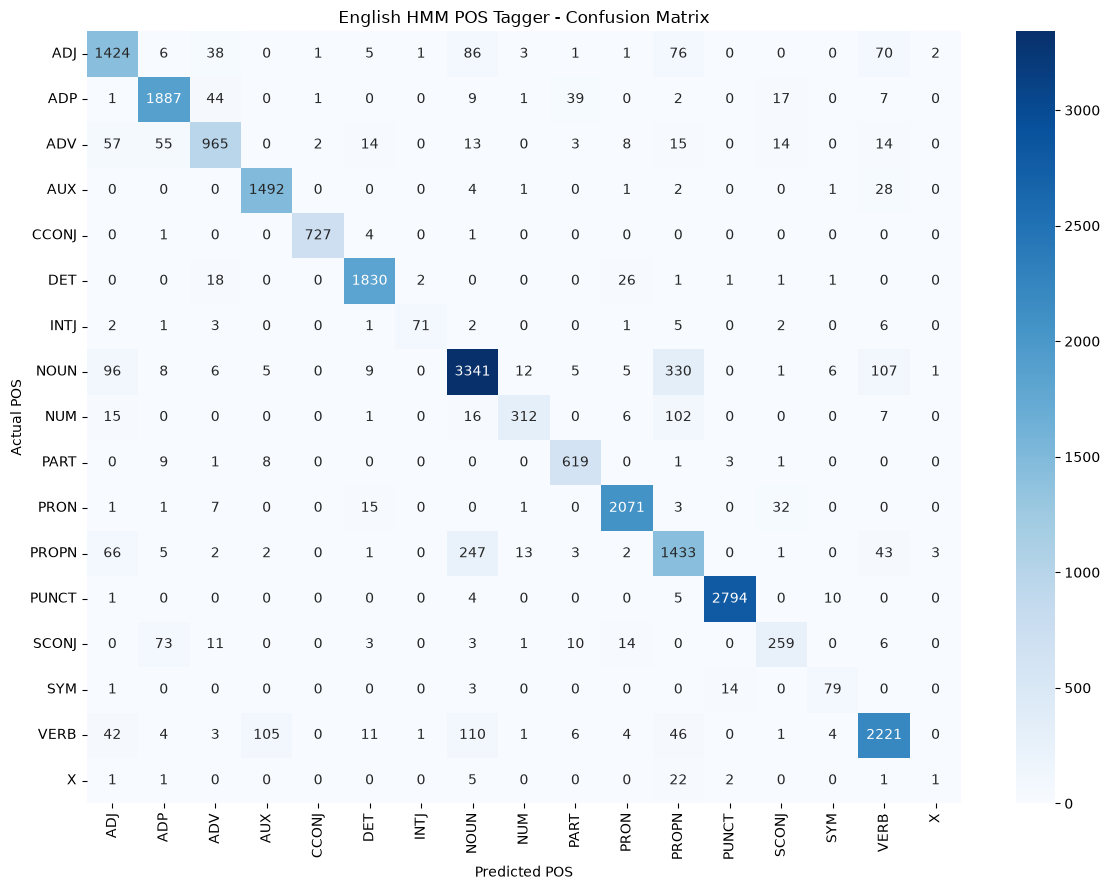

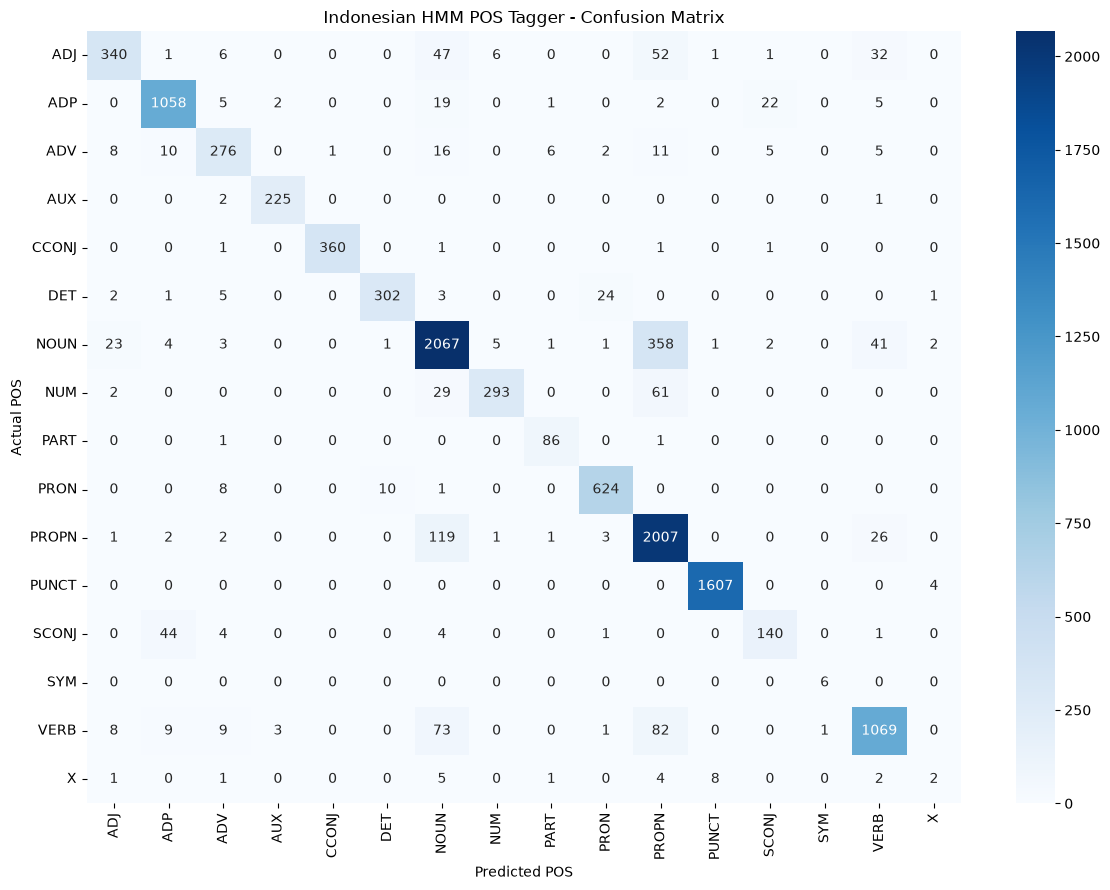

In [31]:
# Confusion matrix plotting function
def plot_confusion_matrix(actual, predicted, language):

    labels = sorted(set(actual) | set(predicted))

    cm = confusion_matrix(
        actual,
        predicted,
        labels=labels
    )

    plt.figure(figsize=(12, 9))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.title(f"{language} HMM POS Tagger - Confusion Matrix")
    plt.xlabel("Predicted POS")
    plt.ylabel("Actual POS")

    plt.tight_layout()
    plt.show()


# English confusion matrix
plot_confusion_matrix(
    eng_actual,
    eng_predicted,
    "English"
)


# Indonesian confusion matrix
plot_confusion_matrix(
    ind_actual,
    ind_predicted,
    "Indonesian"
)

In [32]:
# Extract incorrect predictions
def extract_errors(test_data, predictions, language):

    errors = []

    for sentence_index, (actual_sentence, predicted_sentence) in enumerate(
        zip(test_data, predictions)
    ):

        words = [word for word, tag in actual_sentence]

        sentence_context = " ".join(words)

        for position, ((word, actual_tag), (_, predicted_tag)) in enumerate(
            zip(actual_sentence, predicted_sentence)
        ):

            if actual_tag != predicted_tag:

                errors.append({
                    "Sentence ID": sentence_index + 1,
                    "Word": word,
                    "Sentence Context": sentence_context,
                    "Actual POS": actual_tag,
                    "Predicted POS": predicted_tag,
                    "Position": position + 1,
                    "Language": language
                })

    return pd.DataFrame(errors)

# Extract English errors
eng_errors = extract_errors(
    eng_test_processed,
    eng_predictions,
    "English"
)


# Extract Indonesian errors
ind_errors = extract_errors(
    ind_test_processed,
    ind_predictions,
    "Indonesian"
)


print("English incorrect predictions:", len(eng_errors))
print("Indonesian incorrect predictions:", len(ind_errors))

English incorrect predictions: 2460
Indonesian incorrect predictions: 1285


In [33]:
# Select five English errors
eng_five_errors = eng_errors.head(5)

print("FIVE ENGLISH POS TAGGING ERRORS")
display(eng_five_errors)

# Select five Indonesian errors
ind_five_errors = ind_errors.head(5)

print("FIVE INDONESIAN POS TAGGING ERRORS")
display(ind_five_errors)

FIVE ENGLISH POS TAGGING ERRORS


,Sentence ID,Word,Sentence Context,Actual POS,Predicted POS,Position,Language
0,1,<UNK>,What if Google <UNK> <UNK> <UNK> ?,VERB,PROPN,4,English
1,1,<UNK>,What if Google <UNK> <UNK> <UNK> ?,ADP,PROPN,5,English
2,2,full,What if Google expanded on its search - engine...,ADV,ADJ,18,English
3,3,Watch,[ via Microsoft Watch from Mary <UNK> <UNK> ],PROPN,VERB,4,English
4,4,<UNK>,"( And , by the way , is anybody else just a li...",ADJ,NOUN,14,English


FIVE INDONESIAN POS TAGGING ERRORS


,Sentence ID,Word,Sentence Context,Actual POS,Predicted POS,Position,Language
0,1,<UNK>,<UNK> dari dua singel pertama <UNK> oleh <UNK>...,NOUN,PROPN,1,Indonesian
1,1,artis,<UNK> dari dua singel pertama <UNK> oleh <UNK>...,ADJ,NOUN,20,Indonesian
2,1,<UNK>,<UNK> dari dua singel pertama <UNK> oleh <UNK>...,PROPN,NOUN,30,Indonesian
3,1,telanjang,<UNK> dari dua singel pertama <UNK> oleh <UNK>...,ADJ,VERB,37,Indonesian
4,1,<UNK>,<UNK> dari dua singel pertama <UNK> oleh <UNK>...,VERB,PROPN,43,Indonesian
